In [21]:
import os
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import time as py_time

 tinkoff Api

In [22]:
from tinkoff.invest import Client, CandleInterval, RequestError
from tinkoff.invest.utils import now, quotation_to_decimal

Deep Learning
**Модель** сама по себе рекуррентна с LSTM ячейками

In [23]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [24]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

Данные конфигурации:
Токен берется из *окружения*, FIGI способ записи бумаги (СБЕР), количество дней *(для минуток ограничено 1 днем)*, выбор таймфрейма

In [25]:
TINKOFF_API_TOKEN = "t.He-UEc5Mfe_E2w9CVSlZsCrqyoFacn52Yut_rwdsK8EclvfaxLlju33-26Z2cW22w0dDKNK0cNpxsyXLSGZv-g"
INSTRUMENT_FIGI = "BBG004730N88"
DAYS_HISTORY = 30
CANDLE_TIMEFRAME = CandleInterval.CANDLE_INTERVAL_1_MIN

Параметры LSTM

In [26]:
N_STEPS_IN = 150  # Входные
N_STEPS_OUT = 50  # Выходные

# Параметры обучения
SPLIT_RATIO = 0.8 # 80% данных на обучение, 20% на тест
EPOCHS = 100
BATCH_SIZE = 50
FEATURE_COLUMN = 'close'

Перевод Quotation в float

In [27]:
def decimal_to_float(quotation):
    if quotation and hasattr(quotation, 'units') and hasattr(quotation, 'nano'):
        try:
             return float(quotation_to_decimal(quotation))
        except Exception:
             return float(f"{quotation.units}.{quotation.nano:09d}")
    return np.nan # NaN, если конвертация невозможна



Импорт даных

In [28]:
def get_tinkoff_candles(token, figi, days, interval):
    print(f"Загрузка данных для FIGI: {figi} за последние {days} дней ({interval.name})...")
    all_candles_df = pd.DataFrame()
    try:
        with Client(token) as client:
            end_dt = now() # now() из tinkoff utils
            start_dt = end_dt - timedelta(days=days)

            print(f"Запрос свечей с {start_dt.strftime('%Y-%m-%d %H:%M')} по {end_dt.strftime('%Y-%m-%d %H:%M')}")

            candles_list = []
            for candle in client.get_all_candles(
                figi=figi,
                from_=start_dt,
                to=end_dt,
                interval=interval
            ):
                candles_list.append(candle)
            py_time.sleep(0.1) 

            if not candles_list:
                print("Не удалось загрузить данные. Проверьте FIGI, период и наличие торгов.")
                return None

            df = pd.DataFrame([{
                'time': pd.Timestamp(c.time).tz_localize(None), 
                'open': decimal_to_float(c.open),
                'high': decimal_to_float(c.high),
                'low': decimal_to_float(c.low),
                'close': decimal_to_float(c.close), 
                'volume': c.volume,
                'is_complete': c.is_complete
            } for c in candles_list])

            df = df.set_index('time')
            df = df.sort_index()
            df = df[~df.index.duplicated(keep='first')]
            df.dropna(subset=[FEATURE_COLUMN], inplace=True) # удаление строк, где цена NaN

            print(f"Загружено {len(df)} свечей.")
            if len(df) < N_STEPS_IN + N_STEPS_OUT + 1:
                 print(f"Внимание: Загружено недостаточно данных ({len(df)}) для формирования последовательностей (требуется минимум {N_STEPS_IN + N_STEPS_OUT + 1}).")
                 print("Возможные причины: выходной день, короткий торговый день, нет данных для инструмента.")

            return df

    except RequestError as e:
        print(f"Ошибка API Tinkoff: {e}")
        if hasattr(e, 'details') and e.details:
             print(f"Details (from gRPC): {e.details}")
        if hasattr(e, 'metadata') and e.metadata:
             print(f"Metadata: {e.metadata}")
        return None
    except Exception as e:
        print(f"Произошла ошибка при загрузке данных: {e}")
        import traceback
        traceback.print_exc()
        return None

Дифференцированные данные для LSTM

In [29]:
def prepare_data_diff(df, n_steps_in, n_steps_out, feature_col, split_ratio):
    print("Подготовка дифференцированных данных...")
    min_required_len = n_steps_in + n_steps_out + 1
    if df is None or df.empty or len(df) < min_required_len:
        print(f"Недостаточно данных для подготовки (требуется {min_required_len}, доступно {len(df) if df is not None else 0}).")
        return None, None, None, None, None, None, None, None 

    if feature_col not in df.columns:
        print(f"Ошибка: Колонка '{feature_col}' не найдена.")
        return None, None, None, None, None, None, None, None

    data = df[[feature_col]].copy()
    data['diff'] = data[feature_col].diff()
    original_prices_after_diff = data[feature_col].iloc[1:].values 
    original_indices_after_diff = data.index[1:]
    data = data.dropna()
    diff_values = data[['diff']].values.astype(float)

    if len(diff_values) < n_steps_in + n_steps_out:
        print(f"Недостаточно данных после дифференцирования (требуется {n_steps_in + n_steps_out}, доступно {len(diff_values)}).")
        return None, None, None, None, None, None, None, None

    scaler = MinMaxScaler(feature_range=(0, 1))
    split_idx = int(len(diff_values) * split_ratio)

    if split_idx < n_steps_in:
         print(f"Ошибка: Мало данных для обучающей выборки ({split_idx}) после разделения (требуется {n_steps_in}).")
         return None, None, None, None, None, None, None, None

    scaler.fit(diff_values[:split_idx])
    scaled_data = scaler.transform(diff_values)

    X, y = [], []
    for i in range(len(scaled_data) - n_steps_in - n_steps_out + 1):
        X.append(scaled_data[i:(i + n_steps_in), 0])
        y.append(scaled_data[(i + n_steps_in):(i + n_steps_in + n_steps_out), 0])

    if not X or not y:
        print("Ошибка: Не удалось создать последовательности X и y.")
        return None, None, None, None, None, None, None, None

    X, y = np.array(X), np.array(y)
    X = np.reshape(X, (X.shape[0], X.shape[1], 1))

    split_sequences_idx = int(len(X) * split_ratio)
    if split_sequences_idx == 0:
        print("Ошибка: Недостаточно последовательностей для обучающей выборки.")
        return None, None, None, None, None, None, None, None

    X_train, y_train = X[:split_sequences_idx], y[:split_sequences_idx]
    X_test, y_test_diff = X[split_sequences_idx:], y[split_sequences_idx:]

    original_indices_test_first_step = None
    original_values_test_first_step = None
    prices_before_test_first_step = None

    if len(X_test) > 0:
        num_test_samples = len(X_test)
        test_input_start_idx_in_diff = split_sequences_idx
        first_output_step_original_idx_start = test_input_start_idx_in_diff + n_steps_in + 1

        if first_output_step_original_idx_start + num_test_samples <= len(df):
             original_indices_test_first_step = df.index[first_output_step_original_idx_start : first_output_step_original_idx_start + num_test_samples]
             original_values_test_first_step = df[feature_col].values[first_output_step_original_idx_start : first_output_step_original_idx_start + num_test_samples]
             prices_before_test_first_step = df[feature_col].values[first_output_step_original_idx_start - 1 : first_output_step_original_idx_start -1 + num_test_samples]
        else:
            print("Предупреждение: Не хватает данных в исходном DataFrame для извлечения полных тестовых данных (индексы/значения). Тест может быть неполным.")
            # Try slicing what's available
            available_len = len(df) - first_output_step_original_idx_start
            if available_len > 0:
                 original_indices_test_first_step = df.index[first_output_step_original_idx_start : first_output_step_original_idx_start + available_len]
                 original_values_test_first_step = df[feature_col].values[first_output_step_original_idx_start : first_output_step_original_idx_start + available_len]
                 prices_before_test_first_step = df[feature_col].values[first_output_step_original_idx_start - 1 : first_output_step_original_idx_start -1 + available_len]

    print(f"Размер обучающей выборки (разности): X_train={X_train.shape}, y_train={y_train.shape}")
    print(f"Размер тестовой выборки (разности): X_test={X_test.shape}, y_test={y_test_diff.shape}")

    if len(X_test) == 0 :
        print("Тестовая выборка пуста.")

    return (X_train, y_train, X_test, y_test_diff, scaler,
            original_indices_test_first_step, original_values_test_first_step, prices_before_test_first_step)


Построение модели

In [30]:
def build_lstm_model(n_steps_in, n_steps_out, n_features):
    print("Создание LSTM модели...")
    model = Sequential()
    model.add(LSTM(units=75, activation='tanh', return_sequences=True, input_shape=(n_steps_in, n_features)))
    model.add(Dropout(0.2))
    model.add(LSTM(units=75, activation='tanh'))
    model.add(Dropout(0.2))
    model.add(Dense(units=50, activation='relu'))
    model.add(Dense(units=n_steps_out))
    model.compile(optimizer='adam', loss='mean_squared_error')
    model.summary()
    return model

Построение графиков

In [31]:
def plot_predictions(actual, predicted, indices, title):
    if indices is None or len(indices) == 0 \
       or actual is None or actual.shape[0] == 0 \
       or predicted is None or predicted.shape[0] == 0:
        print("Нет данных для построения графика.")
        return

    actual_plot = actual[:, 0]
    predicted_plot = predicted[:, 0]

    plot_len = min(len(indices), len(actual_plot), len(predicted_plot))
    if plot_len == 0 :
        print("Нет совпадающих данных для графика.")
        return

    plt.figure(figsize=(16, 9))
    plt.plot(indices[:plot_len], actual_plot[:plot_len], label='Реальная цена (close)', color='blue', marker='.', linestyle='-')
    plt.plot(indices[:plot_len], predicted_plot[:plot_len], label='Предсказанная цена (close)', color='red', marker='.', linestyle='--') 

    plt.title(title)
    plt.xlabel('Время')
    plt.ylabel('Цена')
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Загрузка данных

In [32]:
df_raw = get_tinkoff_candles(TINKOFF_API_TOKEN, INSTRUMENT_FIGI, DAYS_HISTORY, CANDLE_TIMEFRAME)

Загрузка данных для FIGI: BBG004730N88 за последние 30 дней (CANDLE_INTERVAL_1_MIN)...
Запрос свечей с 2025-04-12 00:08 по 2025-05-12 00:08
Загружено 30588 свечей.


Проверка на ошибки

In [33]:
if df_raw is None or df_raw.empty:
    print("Не удалось получить данные. Завершение работы.")
    exit()
if len(df_raw) < N_STEPS_IN + N_STEPS_OUT + 1:
     print(f"Недостаточно данных ({len(df_raw)}) после загрузки для продолжения (нужно {N_STEPS_IN + N_STEPS_OUT + 1}).")
     exit()

Подготовка дифференцированных данных

In [34]:
result_prepare = prepare_data_diff(
            df_raw.copy(), N_STEPS_IN, N_STEPS_OUT, FEATURE_COLUMN, SPLIT_RATIO
    )

if result_prepare is None:
    print("Ошибка при подготовке данных (result_prepare is None). Завершение работы.")
    exit()
if result_prepare[0] is None or result_prepare[1] is None or result_prepare[4] is None:
    print("Ошибка при подготовке данных (X_train/y_train/scaler is None). Завершение работы.")
    exit()

Подготовка дифференцированных данных...
Размер обучающей выборки (разности): X_train=(24310, 150, 1), y_train=(24310, 50)
Размер тестовой выборки (разности): X_test=(6078, 150, 1), y_test=(6078, 50)


In [35]:
(X_train, y_train, X_test, y_test_diff, scaler,
     original_indices_test_first_step, original_values_test_first_step,
     prices_before_test_first_step) = result_prepare

if X_train.shape[0] == 0:
     print("Ошибка: Обучающая выборка пуста после подготовки данных.")
     exit()


Создание и обучение модели

In [36]:
model = build_lstm_model(N_STEPS_IN, N_STEPS_OUT, n_features=1)
print("Начало обучения модели...")
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)
print("Обучение завершено.")

Создание LSTM модели...


/home/marcus2tut/.local/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 150, 75)        │        23,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 150, 75)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 75)             │        45,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 75)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 50)             │         3,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 50)             │         2,550 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,750 (291.99 KB)

 Trainable params: 74,750 (291.99 KB)

 Non-trainable params: 0 (0.00 B)

Начало обучения модели...
Epoch 1/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 38s 83ms/step - loss: 0.0452 - val_loss: 0.0014
Epoch 2/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 34s 77ms/step - loss: 0.0017 - val_loss: 0.0014
Epoch 3/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 34s 78ms/step - loss: 0.0014 - val_loss: 0.0014
Epoch 4/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 37s 85ms/step - loss: 0.0013 - val_loss: 0.0014
Epoch 5/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 39s 89ms/step - loss: 0.0013 - val_loss: 0.0014
Epoch 6/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 39s 88ms/step - loss: 0.0013 - val_loss: 0.0014
Epoch 7/100
 52/438 ━━━━━━━━━━━━━━━━━━━━ 33s 86ms/step - loss: 0.0013

KeyboardInterrupt: 

Оценка на тестовой выборке


--- Оценка качества прогноза на тестовых данных (восстановленные цены) ---
191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
RMSE (восстановленные цены, первый шаг): 0.2565
MAPE (восстановленные цены, первый шаг): 0.04%


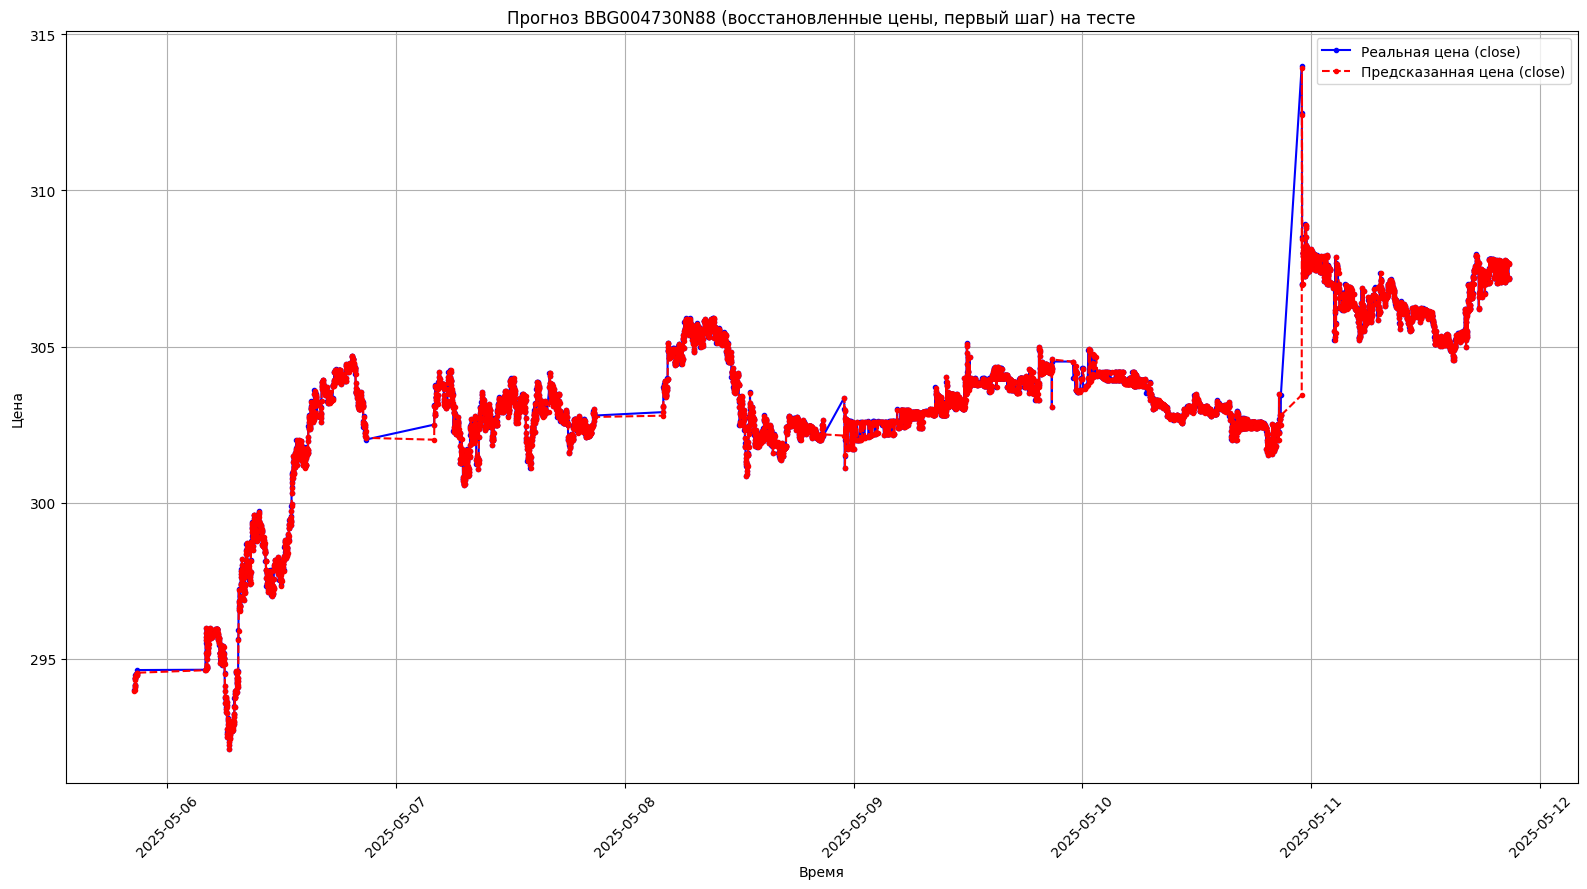

In [17]:
if X_test is not None and X_test.shape[0] > 0 and y_test_diff is not None and y_test_diff.shape[0] > 0 \
   and original_indices_test_first_step is not None and original_values_test_first_step is not None \
   and prices_before_test_first_step is not None:

    print("\n--- Оценка качества прогноза на тестовых данных (восстановленные цены) ---")
    y_pred_diff_scaled = model.predict(X_test)

    if y_pred_diff_scaled.shape[0] == prices_before_test_first_step.shape[0]:
        y_pred_first_diff_unscaled = scaler.inverse_transform(y_pred_diff_scaled[:, 0].reshape(-1, 1)).flatten()
        pred_prices_first_step = prices_before_test_first_step + y_pred_first_diff_unscaled
        actual_prices_first_step_direct = original_values_test_first_step

        # Ensure comparison arrays have the same final length after potential slicing in prepare_data
        min_len = min(len(actual_prices_first_step_direct), len(pred_prices_first_step))
        if min_len > 0 :
            actual_flat = actual_prices_first_step_direct[:min_len].flatten()
            pred_flat = pred_prices_first_step[:min_len].flatten()
            indices_flat = original_indices_test_first_step[:min_len]

            if len(actual_flat) == len(pred_flat):
                rmse_step1 = np.sqrt(mean_squared_error(actual_flat, pred_flat))
                print(f"RMSE (восстановленные цены, первый шаг): {rmse_step1:.4f}")
                epsilon = 1e-10
                mape_step1 = np.mean(np.abs((actual_flat - pred_flat) / (actual_flat + epsilon))) * 100
                print(f"MAPE (восстановленные цены, первый шаг): {mape_step1:.2f}%")

                # 5. Визуализация тестовых результатов (первый шаг)
                if len(indices_flat) > 0:
                     plot_predictions(
                         actual_flat.reshape(-1, 1),
                         pred_flat.reshape(-1, 1),
                         indices_flat,
                         f"Прогноз {INSTRUMENT_FIGI} (восстановленные цены, первый шаг) на тесте" # ! Используем FIGI
                     )
                else:
                     print("Нет индексов для графика теста.")
            else:
                print("Ошибка: Длины массивов не совпадают ПОСЛЕ flatten() и min_len.")
        else:
             print("Ошибка: Недостаточно совпадающих данных для расчета метрик первого шага.")
    else:
         print("Ошибка: не совпадает кол-во предсказанных разностей и цен 'до' для теста")
else:
    print("\nТестовая выборка пуста или не хватает данных для оценки, оценка и визуализация на тесте пропущены.")


Сравнение прогноза и реальных данных

In [18]:
print(f"\n--- Сравнение прогноза и реальных данных для последнего известного часа ({N_STEPS_OUT} минут, дифференцирование) ---")

if len(df_raw) >= N_STEPS_IN + N_STEPS_OUT + 1:
    # Берём N_STEPS_IN+1 последних цен для вычисления разностей
    final_prices_for_input = df_raw[FEATURE_COLUMN].iloc[-(N_STEPS_IN + 1):].values
    # Реальные цены и времена для сравнения
    final_actual_prices_to_compare = df_raw[FEATURE_COLUMN].iloc[-N_STEPS_OUT:].values
    final_actual_times = df_raw.index[-N_STEPS_OUT:]

    # Проверяем, что у нас именно N_STEPS_IN+1 точек
    if final_prices_for_input.shape[0] == N_STEPS_IN + 1:
        # 1) Вычисляем разности (длина = N_STEPS_IN)
        final_input_diffs = np.diff(final_prices_for_input, axis=0)

        if final_input_diffs.shape[0] == N_STEPS_IN:
            # 2) Переформируем в 2D и масштабируем
            final_input_diffs_2d = final_input_diffs.reshape(-1, 1)
            final_input_diffs_scaled = scaler.transform(final_input_diffs_2d)
            final_input_diffs_scaled = final_input_diffs_scaled.reshape((1, N_STEPS_IN, 1))

            # 3) Делаем предсказание разностей
            print("Выполнение прогноза разностей для последнего часа...")
            final_pred_diff_scaled = model.predict(final_input_diffs_scaled)
            final_inv_pred_diff = scaler.inverse_transform(final_pred_diff_scaled.reshape(-1, 1)).flatten()

            # 4) Восстанавливаем цены, начиная с последней известной
            last_price_before_final_hour = final_prices_for_input[-1]
            final_predicted_prices = np.zeros_like(final_inv_pred_diff)
            current_price = last_price_before_final_hour
            for i, diff in enumerate(final_inv_pred_diff):
                current_price += diff
                final_predicted_prices[i] = current_price

            # 5) Сравнение и вывод метрик
            if (len(final_predicted_prices) == len(final_actual_prices_to_compare) 
                    == len(final_actual_times)):
                print(f"Сравнение для последних {N_STEPS_OUT} точек (последний час):")
                print("-" * 65)
                print(f"{'Время':<25} {'Прогноз (восст.)':<18} {'Реальность':<18}")
                print("-" * 65)
                preds, acts = [], []
                for t, p, a in zip(final_actual_times, final_predicted_prices, final_actual_prices_to_compare):
                    print(f"{t.strftime('%Y-%m-%d %H:%M:%S'):<25} {p:<18.4f} {a:<18.4f}")
                    preds.append(float(p))
                    acts.append(float(a))
                print("-" * 65)
                rmse_last = np.sqrt(mean_squared_error(acts, preds))
                mape_last = np.mean(np.abs((np.array(acts) - np.array(preds)) / (np.array(acts) + 1e-10))) * 100
                print(f"RMSE для прогноза последнего часа: {rmse_last:.4f}")
                print(f"MAPE для прогноза последнего часа: {mape_last:.2f}%")
            else:
                print("Ошибка: длины массивов для сравнения не совпадают.")
                print(f"len(pred)={len(final_predicted_prices)}, len(actual)={len(final_actual_prices_to_compare)}, len(times)={len(final_actual_times)}")
        else:
            print(f"Ошибка: получили {final_input_diffs.shape[0]} разностей, ожидалось {N_STEPS_IN}.")
    else:
        print(f"Ошибка: ожидалось {N_STEPS_IN + 1} цен, получено {final_prices_for_input.shape[0]}.")
else:
    print("Недостаточно данных в df_raw для прогноза последнего часа.")



--- Сравнение прогноза и реальных данных для последнего известного часа (5 минут, дифференцирование) ---
Выполнение прогноза разностей для последнего часа...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Сравнение для последних 5 точек (последний час):
-----------------------------------------------------------------
Время                     Прогноз (восст.)   Реальность        
-----------------------------------------------------------------
2025-05-11 20:45:00       307.6930           307.2000          
2025-05-11 20:46:00       307.6745           307.0800          
2025-05-11 20:47:00       307.6726           307.6800          
2025-05-11 20:48:00       307.6945           307.1000          
2025-05-11 20:49:00       307.7072           307.7000          
-----------------------------------------------------------------
RMSE для прогноза последнего часа: 0.4359
MAPE для прогноза последнего часа: 0.11%


In [19]:
def predict_future_prices(model, df, scaler, n_steps_in, n_steps_out, feature_col):
    """
    Предсказывает будущее значение цены на основе последних данных и отображает график прогноза.
    """
    print("\n== Предсказание будущих цен ==")
    
    # Проверка на достаточность данных
    if df is None or df.empty or feature_col not in df.columns:
        print("Ошибка: исходный DataFrame недоступен или не содержит нужной колонки.")
        return
    
    data = df[[feature_col]].copy()
    data['diff'] = data[feature_col].diff()
    data.dropna(inplace=True)
    diff_values = data[['diff']].values.astype(float)

    if len(diff_values) < n_steps_in:
        print(f"Недостаточно данных: требуется минимум {n_steps_in}, доступно {len(diff_values)}.")
        return

    # Последние n_steps_in разностей
    last_sequence = diff_values[-n_steps_in:]
    last_scaled = scaler.transform(last_sequence)

    X_input = np.reshape(last_scaled, (1, n_steps_in, 1))

    predicted_diff = model.predict(X_input, verbose=0)[0]  # Предсказанные разности

    # Обратно в цены
    last_price = df[feature_col].iloc[-1]
    predicted_prices = [last_price + predicted_diff[0]]
    for diff in predicted_diff[1:]:
        predicted_prices.append(predicted_prices[-1] + diff)

    # Временная шкала для прогноза (минутный шаг)
    future_times = [df.index[-1] + timedelta(minutes=i+1) for i in range(n_steps_out)]

    # Построение графика
    plt.figure(figsize=(16, 9))
    plt.plot(df.index[-n_steps_in:], df[feature_col].values[-n_steps_in:], label="Исторические цены", color='blue')
    plt.plot(future_times, predicted_prices, label="Прогнозируемые цены", color='green', linestyle='--', marker='o')
    plt.title("Прогноз цены на следующие {} минут".format(n_steps_out))
    plt.xlabel("Время")
    plt.ylabel("Цена")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()



== Предсказание будущих цен ==


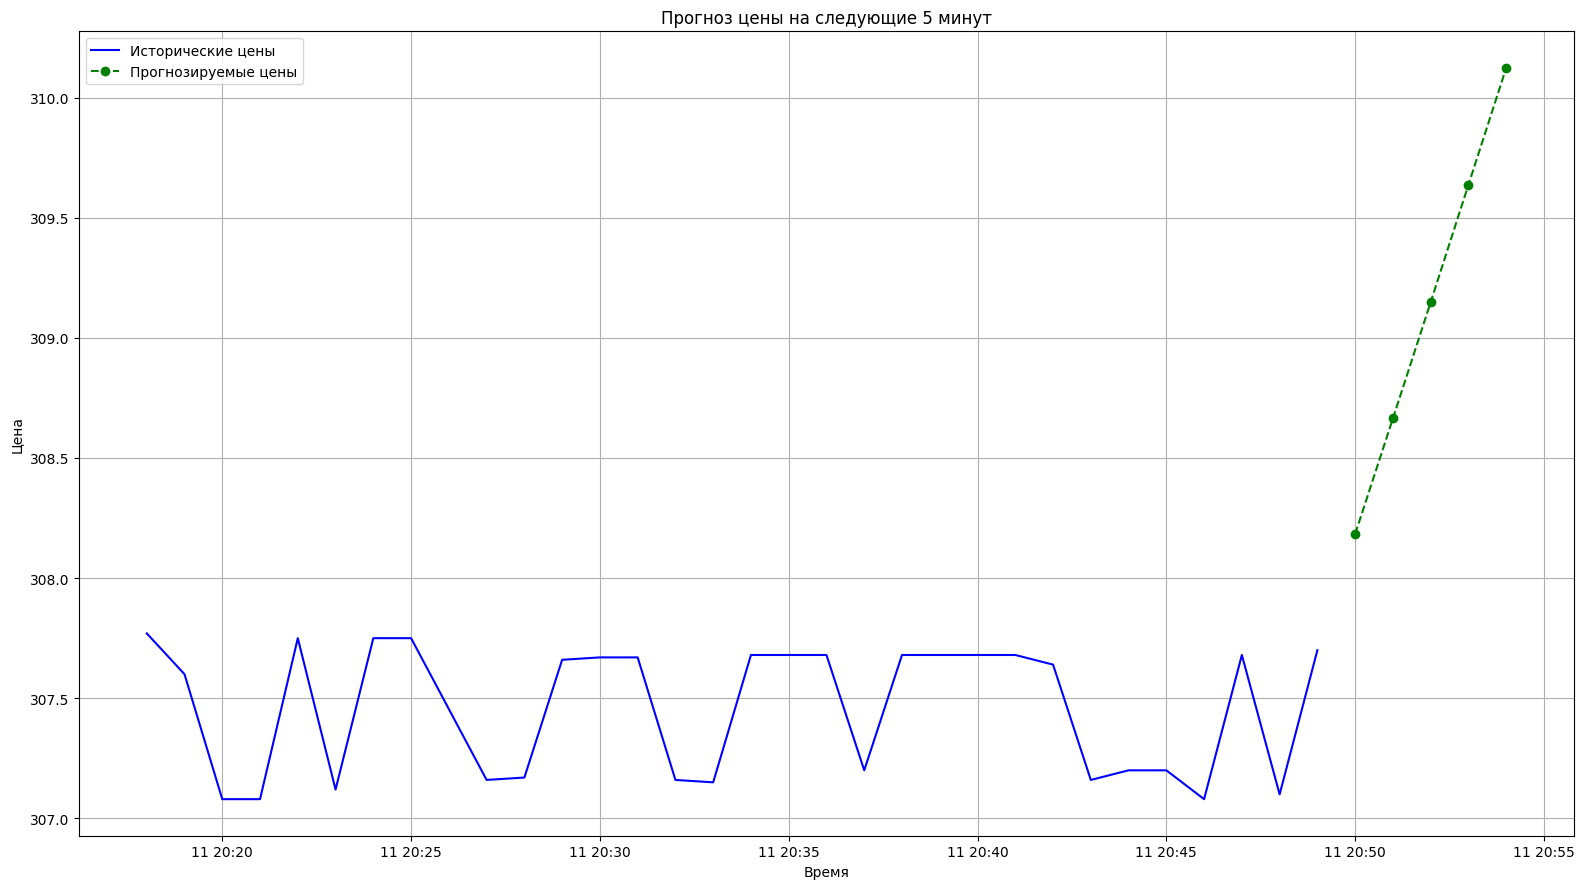

In [20]:
predict_future_prices(model, df_raw, scaler, N_STEPS_IN, N_STEPS_OUT, FEATURE_COLUMN)

